# Evaluation

The evaluation is done after converting predictions back to **dollars** for a better interpretation.

Evaluation criteria:
1. Are models better than simple baselines on the test set?
2. Does volume improve the prediction?
3. Are the differences statistically meaningful, or just noise?
4. Did we meet the business success criteria, and should we deploy?

[`docs/04_evaluation_metrics.md`](../docs/04_evaluation_metrics.md)

In [1]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    sys.path.insert(0, "/Users/owner/Documents/Stock_Price_DL")
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]
    print("Project root:", PROJECT_ROOT)
    Print("Config exists:", (PROJECT_ROOT / "config.py").exists())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import config
from src.evaluate import compare_runs
from src.notebook import show_source
from src import plotting

plotting.set_plot_style()

In [3]:
""" Inspect compare runs """
show_source(compare_runs)


<details>
<summary>View implementation of <code>compare_runs</code></summary>

```python
def compare_runs(
    run_names: Optional[Iterable[str]] = None,
    artifacts_dir: Path = config.ARTIFACTS_DIR,
    split: str = "test",
    save: bool = True,
) -> pd.DataFrame:
    """
    Evaluate saved runs on the same split, add the baselines, and return one
    table sorted by RMSE. Also saves each run's predictions to
    artifacts/<run>/predictions_<split>.csv and the table to artifacts/metrics.csv.

    Each run is evaluated with ITS OWN saved scalers and settings (from
    metadata.json), just as it would be in deployment.
    """
    artifacts_dir = Path(artifacts_dir)
    if run_names is None:
        run_dirs = list_artifact_dirs(artifacts_dir)
    else:
        run_dirs = [artifacts_dir / name for name in run_names]
    if not run_dirs:
        raise FileNotFoundError(f"No trained runs found in {artifacts_dir}.")

    rows = []
    baseline_table = None
    reference_dates = None
    reference_actual = None

    for run_dir in run_dirs:
        arts = load_artifacts(run_dir)
        meta = arts["metadata"]
        data = load_prepared_data(
            use_volume=meta["use_volume"],
            target_mode=meta["target_mode"],
            lookback=meta["lookback"],
            start_date=meta["start_date"],
            feature_scaler=arts["feature_scaler"],
            target_scaler=arts["target_scaler"],
            verbose=False,
        )
        pred_df = predict_split(arts["model"], data, split)

        if reference_dates is None:
            reference_dates = pred_df.index.copy()
            reference_actual = pred_df["actual"].to_numpy().copy()
        else:
            if not pred_df.index.equals(reference_dates):
                raise ValueError(
                    f"Test dates do not match for run: {run_dir.name}"
                )
            if not np.allclose(
                pred_df["actual"].to_numpy(),
                reference_actual,
                rtol=0,
                atol=1e-8,
            ):
                raise ValueError(
                    f"Actual closing prices do not match for run: {run_dir.name}"
                )

        pred_df.to_csv(run_dir / f"predictions_{split}.csv")
        m = regression_metrics(pred_df["actual"], pred_df["predicted"], pred_df["close_t"])
        m.update(
            {
                "run": run_dir.name,
                "kind": "model",
                "model": meta["model_name"],
                "features": "close + volume" if meta["use_volume"] else "close",
                "target_mode": meta["target_mode"],
                # Best validation loss: the number to use for MODEL SELECTION.
                # Test metrics only report how the selected model performs.
                "val_loss": meta.get("best_val_loss"),
                "parameters": meta.get("n_parameters"),
                "epochs": meta.get("epochs_run"),
            }
        )
        rows.append(m)

        # Baselines do not depend on the model, only on the test days.
        # All runs share the same days when they share START_DATE and LOOKBACK.
        if baseline_table is None:
            baseline_table = baseline_metrics(pred_df)

    table = pd.concat([pd.DataFrame(rows).set_index("run"), baseline_table])
    columns = ["kind", "model", "features", "target_mode"] + METRIC_COLUMNS + ["val_loss", "parameters", "epochs"]
    table = table.reindex(columns=columns).sort_values("RMSE")
    # Nullable integers: baselines have no parameter/epoch counts (shown as <NA> instead of 7777.0).
    table[["parameters", "epochs"]] = table[["parameters", "epochs"]].astype("Int64")

    if save:
        artifacts_dir.mkdir(parents=True, exist_ok=True)
        table.to_csv(artifacts_dir / "metrics.csv")
    return table

```

</details>


## 1. Comparison table (test set)

**Baselines** (no machine learning):
- **naive:** tomorrow's close = today's close (the "random walk" forecast)
- **random walk + drift:** today's close × the average daily growth observed in training
- **5-day moving average:** mean of the last 5 closes

**Metrics:** `MAE` and `RMSE` in dollars (lower is better), `MAPE_%` in percent (lower is better), and `DirAcc_%`, the percentage of days with the correct up/down direction (higher is better; it is undefined for the naive baseline, which never moves).

In [8]:
table = compare_runs(run_names=[
    "cnn_close", 
    "cnn_close_volume",
    "lstm_close",
    "lstm_close_volume",
    "gru_close",
    "gru_close_volume"
    ])
table.round(4)


/opt/anaconda3/envs/stock_eval312/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/envs/stock_eval312/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/anaconda3/envs/stock_eval312/lib/python3.12/site-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version

,kind,model,features,target_mode,MAE,RMSE,MAPE_%,DirAcc_%,val_loss,parameters,epochs
run,,,,,,,,,,,
baseline: random walk + drift,baseline,NaN,NaN,NaN,2.8363,4.1520,1.1852,55.2215,NaN,<NA>,<NA>
baseline: naive (tomorrow = today),baseline,NaN,NaN,NaN,2.8533,4.1577,1.1918,NaN,NaN,<NA>,<NA>
cnn_close_volume,model,cnn,close + volume,log_return,2.8679,4.1737,1.1962,49.6835,0.3881,769,21
cnn_close,model,cnn,close,log_return,2.8807,4.1837,1.2010,46.8354,0.3881,449,20
gru_close_volume,model,gru,close + volume,log_return,2.9249,4.2178,1.2170,45.5696,0.3872,13121,12
lstm_close,model,lstm,close,log_return,3.0385,4.3053,1.2606,44.7785,0.3868,16961,14
lstm_close_volume,model,lstm,close + volume,log_return,3.1154,4.3693,1.2897,45.0949,0.3864,17217,15
gru_close,model,gru,close,log_return,3.3906,4.6419,1.3860,44.9367,0.3870,12929,19
baseline: 5-day moving average,baseline,NaN,NaN,NaN,4.7336,6.4502,1.9777,48.8924,NaN,<NA>,<NA>


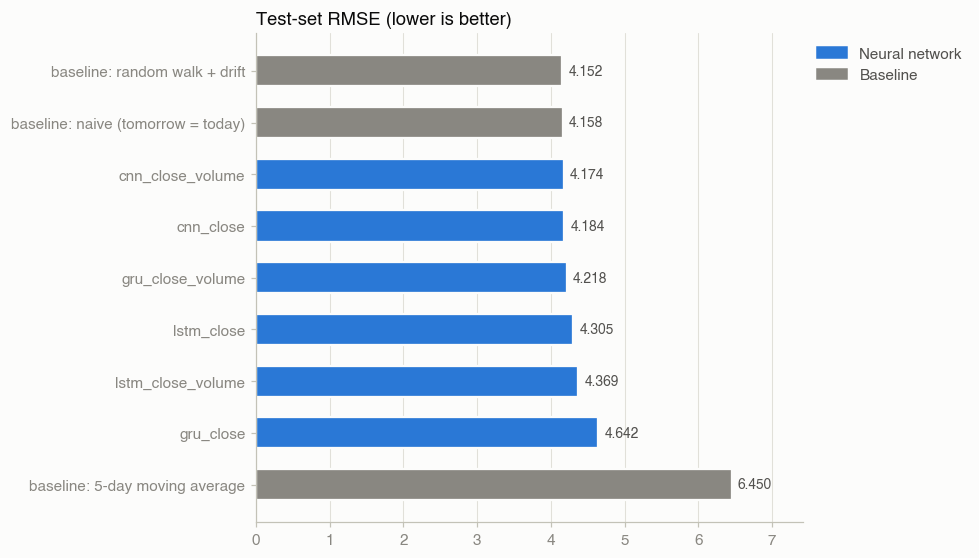

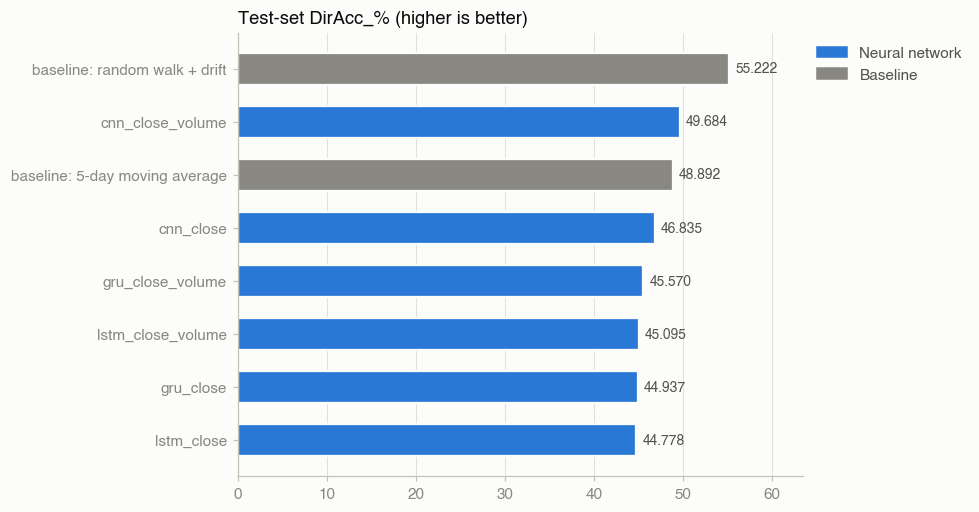

In [9]:
fig = plotting.plot_metric_comparison(table, "RMSE")
plotting.save_figure(fig, "comparison_rmse.png")
plt.show()

fig = plotting.plot_metric_comparison(table, "DirAcc_%", higher_is_better=True)
plotting.save_figure(fig, "comparison_directional_accuracy.png")
plt.show()

In [10]:
models = table[(table["kind"] == "model") & (table["target_mode"] == "log_return")]
naive_rmse = table.loc["baseline: naive (tomorrow = today)", "RMSE"]
drift_rmse = table.loc["baseline: random walk + drift", "RMSE"]
# Model SELECTION uses the validation loss.
# The test set only REPORTS how the selected model performs.
best_run = models["val_loss"].idxmin()
best_test_run = models["RMSE"].idxmin()

print(f"Selected network (lowest validation loss): {best_run}  (test RMSE ${models.loc[best_run, 'RMSE']:.4f})")
print(f"Lowest test RMSE (information only)      : {best_test_run}  (test RMSE ${models.loc[best_test_run, 'RMSE']:.4f})")
print(f"Naive baseline RMSE : ${naive_rmse:.4f}")
print(f"Drift baseline RMSE : ${drift_rmse:.4f}")
print(f"Improvement of selected model over naive: {(1 - models.loc[best_run, 'RMSE'] / naive_rmse) * 100:+.2f}%")
print(f"Models better than naive: {int((models['RMSE'] < naive_rmse).sum())} of {len(models)}")
print(f"Models better than drift: {int((models['RMSE'] < drift_rmse).sum())} of {len(models)}")

Selected network (lowest validation loss): lstm_close_volume  (test RMSE $4.3693)
Lowest test RMSE (information only)      : cnn_close_volume  (test RMSE $4.1737)
Naive baseline RMSE : $4.1577
Drift baseline RMSE : $4.1520
Improvement of selected model over naive: -5.09%
Models better than naive: 0 of 6
Models better than drift: 0 of 6


All models and baselines are within a few cents of each other. Most of the day to day price movement is unpredictable noise, so a good model can only partly reduce the naive error. That is what the Efficient Market Hypothesis leads us to expect as explained in [`docs/02_time_series_concepts.md`](../docs/02_time_series_concepts.md)

## 2. Comparing price only vs price + volume
Compare each architecture with itself: price only vs price + volume.

In [11]:
rmse = models.pivot_table(index="model", columns="features", values="RMSE")
diracc = models.pivot_table(index="model", columns="features", values="DirAcc_%")
volume_effect = pd.DataFrame({
    "RMSE close": rmse.get("close", float("nan")),
    "RMSE close+volume": rmse["close + volume"],
    "RMSE change with volume ($)": rmse["close + volume"] - rmse.get("close", float("nan")),
    "DirAcc close (%)": diracc.get("close", float("nan")),
    "DirAcc close+volume (%)": diracc["close + volume"],
})
volume_effect.round(4)

,RMSE close,RMSE close+volume,RMSE change with volume ($),DirAcc close (%),DirAcc close+volume (%)
model,,,,,
cnn,4.1837,4.1737,-0.0100,46.8354,49.6835
gru,4.6419,4.2178,-0.4241,44.9367,45.5696
lstm,4.3053,4.3693,0.0640,44.7785,45.0949


A negative "RMSE change" means volume helped. Before concluding anything, we check whether the differences are real.



## 3. The Diebold-Mariano test
The **Diebold-Mariano (DM) test** compares two forecasts made on the same days. For each day, compute the loss differential

$$d_t = e_{A,t}^2 - e_{B,t}^2$$

If both forecasts are equally accurate, the mean of $d_t$ is 0. The DM statistic is $\bar d / \sqrt{\widehat{\text{Var}}(d)/n}$, which is approximately standard normal.
- **Negative DM:** forecast A (the model) has lower squared error than B (the naive baseline).
- **p-value < 0.05:** the difference is unlikely to be pure chance.

(We use the simple version for 1-day-ahead forecasts.)

In [12]:
def diebold_mariano(actual, pred_a, pred_b):
    """Simple DM test for 1-step-ahead forecasts with squared-error loss."""
    d = (pred_a - actual) ** 2 - (pred_b - actual) ** 2
    dm = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    p_value = 2 * (1 - stats.norm.cdf(abs(dm)))
    return dm, p_value

def load_predictions(run):
    return pd.read_csv(config.ARTIFACTS_DIR / run / "predictions_test.csv", index_col=0, parse_dates=True)

rows = []
for run in models.index:
    preds = load_predictions(run)
    dm_naive, p_naive = diebold_mariano(preds["actual"], preds["predicted"], preds["naive"])
    dm_drift, p_drift = diebold_mariano(preds["actual"], preds["predicted"], preds["drift"])
    rows.append({"run": run, "DM vs naive": dm_naive, "p vs naive": p_naive,
                 "DM vs drift": dm_drift, "p vs drift": p_drift})
dm_table = pd.DataFrame(rows).set_index("run")
dm_table.round(4)

,DM vs naive,p vs naive,DM vs drift,p vs drift
run,,,,
cnn_close_volume,1.0591,0.2895,0.8831,0.3772
cnn_close,1.4776,0.1395,1.1554,0.2479
gru_close_volume,2.1986,0.0279,1.7798,0.0751
lstm_close,3.3960,0.0007,2.8681,0.0041
lstm_close_volume,4.0423,0.0001,3.4890,0.0005
gru_close,5.5405,0.0000,5.0892,0.0000


In [ ]:
# Close-only model comparison is unavailable in the final three-model evaluation.
print("Volume vs. no-volume statistical comparison not available for the selected final runs.")


## 4. A closer look at the selected model

This is the run with the lowest **validation** loss: the one we would deploy.

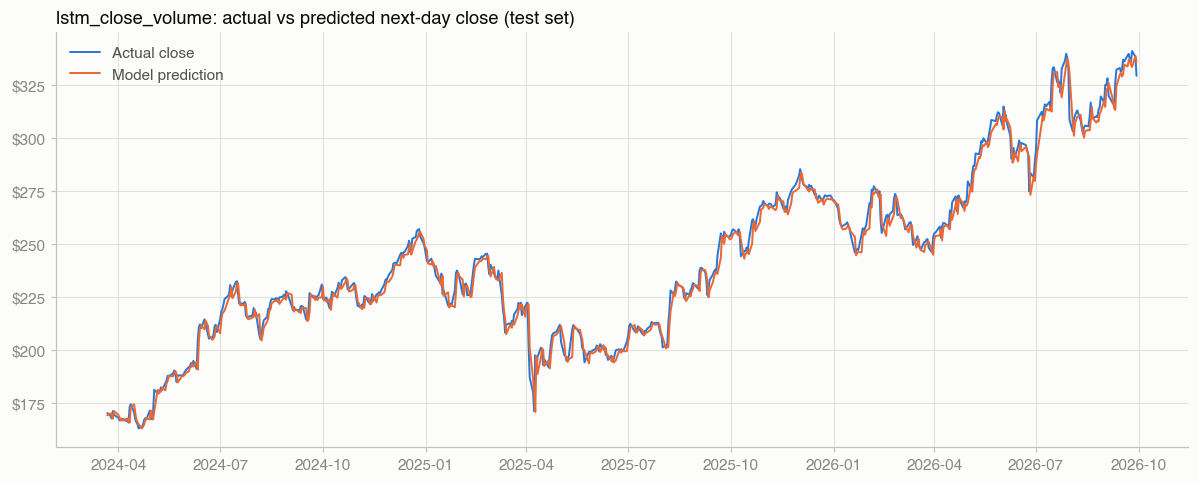

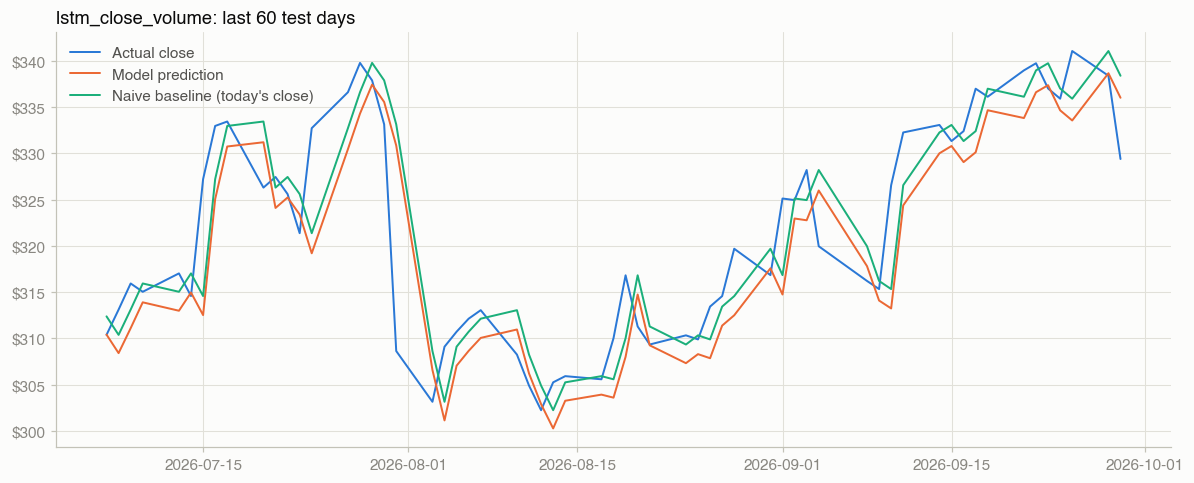

In [13]:
preds = load_predictions(best_run)
fig = plotting.plot_predictions(preds, f"{best_run}: actual vs predicted next-day close (test set)")
plotting.save_figure(fig, f"{best_run}_test_predictions.png")
plt.show()

fig = plotting.plot_predictions(preds, f"{best_run}: last 60 test days", last_n=60, show_naive=True)
plotting.save_figure(fig, f"{best_run}_last60.png")
plt.show()

The prediction line follows the actual line, however it mostly follows the price one day late, almost on top of the naive baseline. That is why charts alone are misleading and the reason why we compare against baselines.

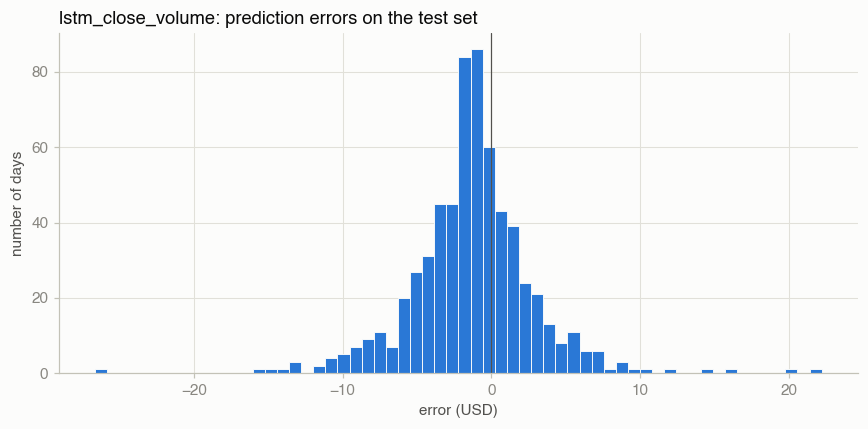

In [14]:
fig = plotting.plot_residuals(preds, f"{best_run}: prediction errors on the test set")
plotting.save_figure(fig, f"{best_run}_residuals.png")
plt.show()

In [15]:
pred_ret = np.log(preds["predicted"] / preds["close_t"])
actual_ret = np.log(preds["actual"] / preds["close_t"])
pd.Series({
    "std of actual daily returns (%)": actual_ret.std() * 100,
    "std of predicted daily returns (%)": pred_ret.std() * 100,
    "correlation(predicted, actual return)": pred_ret.corr(actual_ret),
    "share of predicted up days (%)": (pred_ret > 0).mean() * 100,
    "share of actual up days (%)": (actual_ret > 0).mean() * 100,
}).round(4).to_frame("value")

,value
std of actual daily returns (%),1.7633
std of predicted daily returns (%),0.1688
"correlation(predicted, actual return)",0.0539
share of predicted up days (%),0.7911
share of actual up days (%),55.2215


The predicted returns vary far less than the actual returns. When the target is mostly noise, the loss minimizing prediction is close to the *average* return, so the network learns to be cautious. The correlation between predicted and actual returns shows how much real signal it found.

## 5. Evaluation against the business success criteria

In [16]:
best_model_name = models.loc[best_run, "model"]
share_up_days = (actual_ret > 0).mean() * 100
criteria = pd.DataFrame([
    {"criterion": "Selected model RMSE < naive baseline RMSE",
     "result": f"{models.loc[best_run, 'RMSE']:.4f} vs {naive_rmse:.4f}",
     "met": bool(models.loc[best_run, "RMSE"] < naive_rmse)},
    {"criterion": "Improvement over naive is statistically significant (DM, 5%)",
     "result": f"p = {dm_table.loc[best_run, 'p vs naive']:.3f}",
     "met": bool(dm_table.loc[best_run, "p vs naive"] < 0.05 and dm_table.loc[best_run, "DM vs naive"] < 0)},
    {"criterion": "Directional accuracy > share of up days",
     "result": f"{models.loc[best_run, 'DirAcc_%']:.1f}% vs {share_up_days:.1f}%",
     "met": bool(models.loc[best_run, "DirAcc_%"] > share_up_days)},
    {"criterion": f"Volume lowers RMSE ({best_model_name})",
     "result": f"{volume_effect.loc[best_model_name, 'RMSE change with volume ($)']:+.4f} $",
     "met": bool(volume_effect.loc[best_model_name, "RMSE change with volume ($)"] < 0)},
]).set_index("criterion")
criteria

,result,met
criterion,,
Selected model RMSE < naive baseline RMSE,4.3693 vs 4.1577,False
"Improvement over naive is statistically significant (DM, 5%)",p = 0.000,False
Directional accuracy > share of up days,45.1% vs 55.2%,False
Volume lowers RMSE (lstm),+0.0640 $,False


## 6. Decision and next steps

**Technical decision.** The pipeline is correct and reproducible. The run with the lowest **validation** loss is selected for deployment; the test set is used only to report its performance.

**Business decision.** Not all the criteria above showed a statistically significant improvement over the baselines, the conclusion is:
- *With past prices and volume alone, the neural networks do not reliably surpass a random walk for next day AAPL closes.*

That is a **valid and valuable result**: it is what finance theory predicts, and it tells us that extra complexity on the same inputs is unlikely to help. 
CRISP-DM is iterative, so the next loop should go back to **Data Understanding / Preparation** with new information: market context, volatility indices, news sentiment, or a reframed target such as direction or volatility.

Next: [`05_deployment.ipynb`](05_deployment.ipynb)